<a href="https://colab.research.google.com/github/harshitadalne/AI-Practicals-Python-/blob/main/NNDL_Practical_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q opencv-python tensorflow_hub matplotlib

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


Loading model...
Model loaded successfully!
  40960/Unknown 0s 3us/step

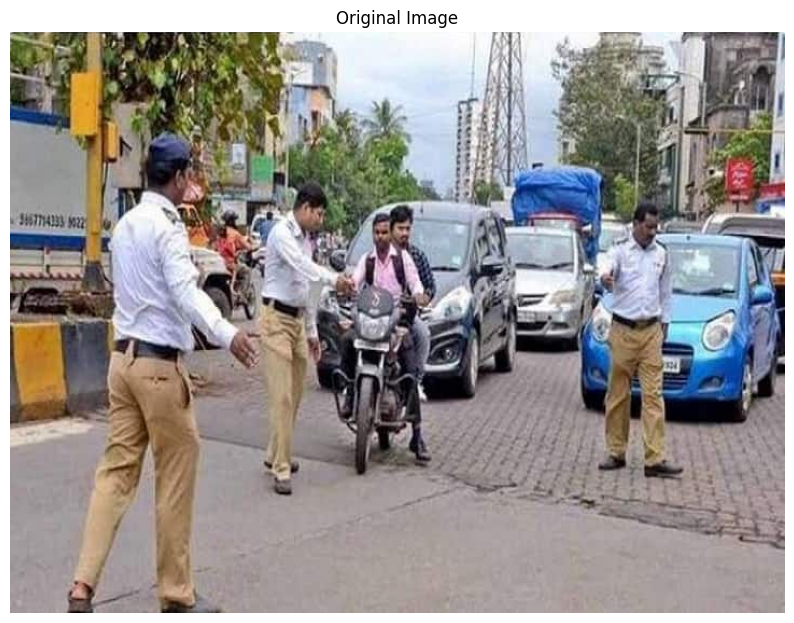

Detected 100 objects.


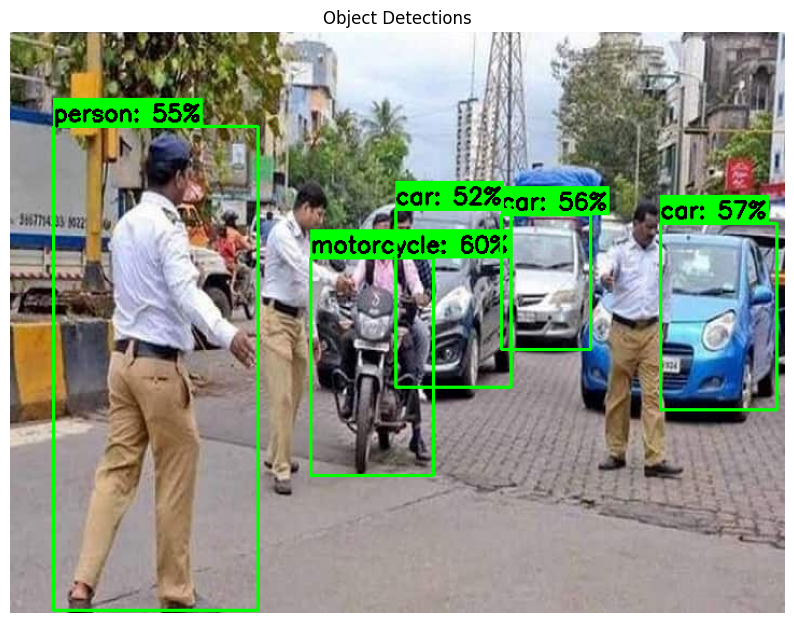

In [ ]:
import tensorflow as tf
import tensorflow_hub as hub
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Loading model...")

detector = hub.load(
    "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/fpnlite_320x320/1"
)

print("Model loaded successfully!")

def load_image_from_url(image_url):
    image_path = tf.keras.utils.get_file(
        origin=image_url
    )
    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image_np = np.array(image_rgb)
    return image_np

image_url = "https://feeds.abplive.com/onecms/images/uploaded-images/2022/06/08/cba50dc1f15b89efcce65f6a9ec7350b_original.JPG"

image_np = load_image_from_url(image_url)

plt.figure(figsize=(10, 8))
plt.imshow(image_np)
plt.axis("off")
plt.title("Original Image")
plt.show()

input_tensor = tf.convert_to_tensor(image_np)
input_tensor = input_tensor[tf.newaxis, ...]

result = detector(input_tensor)

result = {
    key: value.numpy()
    for key, value in result.items()
}

boxes = result["detection_boxes"][0]
scores = result["detection_scores"][0]
class_ids = result["detection_classes"][0]
num_detections = int(result["num_detections"][0])

print(f"Detected {num_detections} objects.")

def draw_boxes_and_labels(
    image,
    boxes,
    classes,
    scores,
    num_detections,
    category_index,
    min_score_thresh=0.5
):
    image_copy = np.copy(image)

    im_height, im_width, _ = image_copy.shape

    for i in range(num_detections):

        if scores[i] > min_score_thresh:

            ymin, xmin, ymax, xmax = boxes[i]

            ymin = int(ymin * im_height)
            xmin = int(xmin * im_width)
            ymax = int(ymax * im_height)
            xmax = int(xmax * im_width)

            class_name = category_index.get(
                int(classes[i]),
                {"name": "N/A"}
            )["name"]

            label = f"{class_name}: {int(scores[i] * 100)}%"

            cv2.rectangle(
                image_copy,
                (xmin, ymin),
                (xmax, ymax),
                (0, 255, 0),
                2
            )

            (w, h), _ = cv2.getTextSize(
                label,
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                2
            )

            cv2.rectangle(
                image_copy,
                (xmin, ymin - h - 10),
                (xmin + w, ymin),
                (0, 255, 0),
                -1
            )

            cv2.putText(
                image_copy,
                label,
                (xmin, ymin - 5),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 0, 0),
                2
            )

    return image_copy

category_index = {
    1: {"id": 1, "name": "person"},
    2: {"id": 2, "name": "bicycle"},
    3: {"id": 3, "name": "car"},
    4: {"id": 4, "name": "motorcycle"},
    5: {"id": 5, "name": "airplane"},
    15: {"id": 15, "name": "cat"},
    16: {"id": 16, "name": "dog"},
    17: {"id": 17, "name": "horse"},
    18: {"id": 18, "name": "sheep"},
    19: {"id": 19, "name": "cow"},
    20: {"id": 20, "name": "elephant"},
    21: {"id": 21, "name": "bear"}
}

image_with_detections = draw_boxes_and_labels(
    image_np,
    boxes,
    class_ids,
    scores,
    num_detections,
    category_index
)

plt.figure(figsize=(10, 8))
plt.imshow(image_with_detections)
plt.axis("off")
plt.title("Object Detections")
plt.show()